# Land-cover classification on EuroSAT

This notebook trains the model behind the **Land Change** app. Two classifiers are trained on the
EuroSAT RGB dataset (27,000 Sentinel-2 image tiles of 64x64 pixels, 10 land-cover classes) and compared:

1. a small convolutional network written and trained from scratch (about 95 thousand parameters), and
2. a ResNet18 pre-trained on ImageNet and fine-tuned on the same data (about 11 million parameters).

Both use the same stratified 70/15/15 split. The test set is touched once, at the end.

**About the saved outputs.** They come from the original training run on a Colab T4 GPU; the weights
from that run are the ones the app uses. After the run, the printed labels were translated from Turkish
to English and the two training-curve figures were redrawn from the logged per-epoch values.
No number was changed. The output of the last cell (confident errors) was cleared; run the evaluation cells to reproduce it.
Running the notebook again retrains both models, so
accuracies will differ slightly from the ones shown.

## 1. Setup and data

In [ ]:
# Optional: mount Google Drive to keep the trained weights and figures between sessions.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
from collections import Counter
from torchvision import datasets

raw = datasets.EuroSAT(root="data", download=True)

print("Total images:", len(raw))
counts = Counter(raw.targets)
for i, name in enumerate(raw.classes):
    print(f"{name:25s} {counts[i]}")

100%|██████████| 94.3M/94.3M [00:01<00:00, 89.0MB/s]


Total images: 27000
AnnualCrop                3000
Forest                    3000
HerbaceousVegetation      3000
Highway                   2500
Industrial                2500
Pasture                   2000
PermanentCrop             2500
Residential               3000
River                     2500
SeaLake                   3000


One random example from each class.

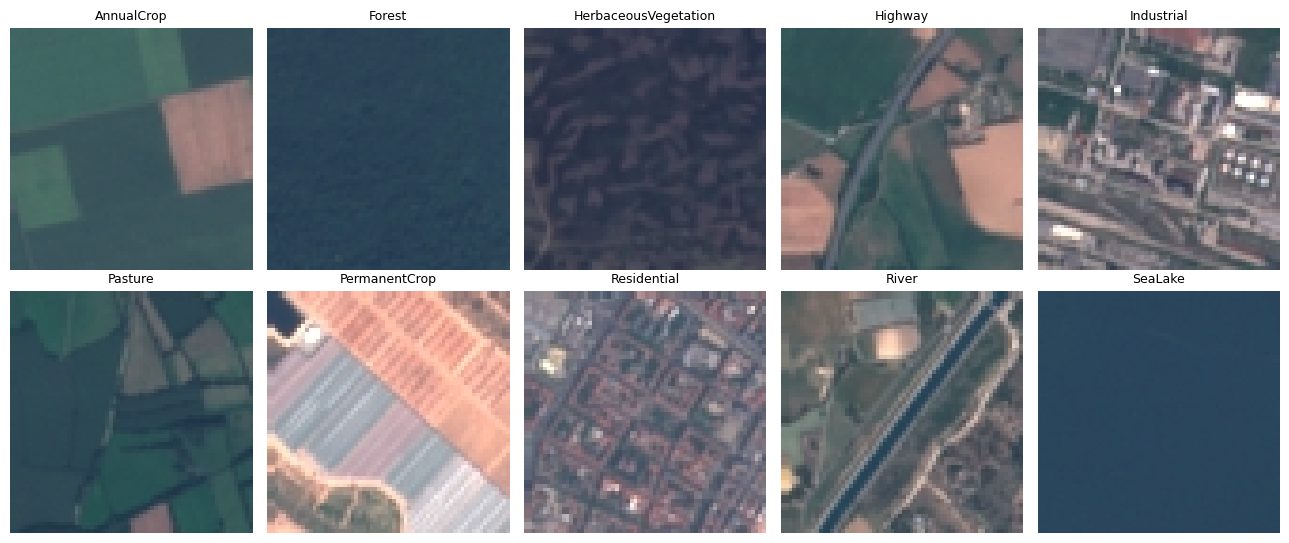

In [ ]:
import random
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
for cls, ax in enumerate(axes.flat):
    idx = random.choice([i for i, t in enumerate(raw.targets) if t == cls])
    img, _ = raw[idx]
    ax.imshow(img)
    ax.set_title(raw.classes[cls], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("samples.png", dpi=150)
plt.show()

A stratified split keeps the class proportions equal in every subset. The fixed seed makes the split
reproducible, so both models are trained and tested on exactly the same images.

In [ ]:
from sklearn.model_selection import train_test_split

all_idx = list(range(len(raw)))
train_idx, rest_idx = train_test_split(
    all_idx, test_size=0.30, stratify=raw.targets, random_state=42)

rest_labels = [raw.targets[i] for i in rest_idx]
val_idx, test_idx = train_test_split(
    rest_idx, test_size=0.50, stratify=rest_labels, random_state=42)

print(len(train_idx), len(val_idx), len(test_idx))

18900 4050 4050


Random flips are applied to training images only. Satellite tiles have no natural "up", so horizontal
and vertical flips are both safe. Inputs are normalised with the ImageNet statistics the pre-trained
network expects.

In [ ]:
from torch.utils.data import DataLoader, Subset
from torchvision import transforms

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = Subset(datasets.EuroSAT("data", transform=train_tf), train_idx)
val_ds = Subset(datasets.EuroSAT("data", transform=eval_tf), val_idx)
test_ds = Subset(datasets.EuroSAT("data", transform=eval_tf), test_idx)

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)

x, y = next(iter(train_dl))
print(x.shape, y.shape)

torch.Size([64, 3, 64, 64]) torch.Size([64])


## 2. A small CNN from scratch

Three convolution blocks halve the resolution (64 → 32 → 16 → 8) while widening the channels, followed
by global average pooling and a linear layer. This is the baseline.

In [ ]:
import torch.nn as nn

class SmallCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, 3, padding=1),
                nn.BatchNorm2d(c_out),
                nn.ReLU(),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Dropout(0.3), nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.head(self.features(x))

torch.manual_seed(42)
model = SmallCNN().to(device)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 94986


`fit` trains with Adam and a cosine learning-rate schedule, evaluates on the validation set after every
epoch and keeps the weights of the best epoch. With a constant learning rate the validation accuracy
of this small network swung by several points between epochs; the schedule removed most of that.

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n


def fit(model, name, epochs=15, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    history, best = [], 0.0
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_dl, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl, criterion)
        scheduler.step()
        history.append((tr_loss, tr_acc, va_loss, va_acc))
        if va_acc > best:
            best = va_acc
            torch.save(model.state_dict(), f"{name}.pt")
        print(f"{ep:2d} | train {tr_loss:.3f} / {tr_acc:.3f} | val {va_loss:.3f} / {va_acc:.3f}")
    print("Best validation accuracy:", round(best, 4))
    return history

In [ ]:
cnn_history = fit(model, "small_cnn", epochs=20)

 1 | train 0.972 / 0.670 | val 0.718 / 0.745
 2 | train 0.686 / 0.763 | val 0.627 / 0.789
 3 | train 0.601 / 0.791 | val 0.621 / 0.768
 4 | train 0.542 / 0.813 | val 0.470 / 0.836
 5 | train 0.483 / 0.833 | val 0.414 / 0.857
 6 | train 0.457 / 0.842 | val 0.695 / 0.749
 7 | train 0.425 / 0.856 | val 0.374 / 0.867
 8 | train 0.394 / 0.865 | val 0.351 / 0.880
 9 | train 0.375 / 0.872 | val 0.294 / 0.901
10 | train 0.344 / 0.881 | val 0.359 / 0.877
11 | train 0.330 / 0.888 | val 0.288 / 0.903
12 | train 0.320 / 0.891 | val 0.264 / 0.912
13 | train 0.294 / 0.899 | val 0.290 / 0.899
14 | train 0.291 / 0.899 | val 0.249 / 0.915
15 | train 0.274 / 0.908 | val 0.257 / 0.907
16 | train 0.260 / 0.914 | val 0.216 / 0.927
17 | train 0.252 / 0.913 | val 0.207 / 0.930
18 | train 0.248 / 0.917 | val 0.204 / 0.929
19 | train 0.245 / 0.916 | val 0.203 / 0.935
20 | train 0.238 / 0.921 | val 0.199 / 0.935
Best validation accuracy: 0.9353


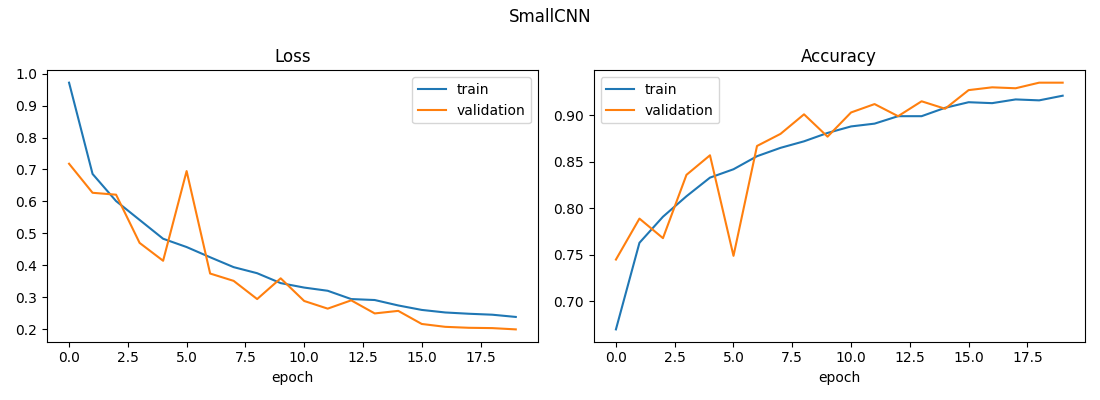

In [ ]:
def plot_history(history, title, path):
    tr_loss, tr_acc, va_loss, va_acc = zip(*history)
    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
    a.plot(tr_loss, label="train"); a.plot(va_loss, label="validation")
    a.set_title("Loss"); a.set_xlabel("epoch"); a.legend()
    b.plot(tr_acc, label="train"); b.plot(va_acc, label="validation")
    b.set_title("Accuracy"); b.set_xlabel("epoch"); b.legend()
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(path, dpi=150); plt.show()

plot_history(cnn_history, "SmallCNN", "small_cnn_curves.png")

In [ ]:
# Optional: copy the artefacts to Google Drive.
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/eurosat
!cp small_cnn.pt small_cnn_curves.png samples.png /content/drive/MyDrive/eurosat/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. ResNet18, pre-trained

The ImageNet classification head is replaced by a 10-class layer and the whole network is fine-tuned
with a ten times smaller learning rate, so the pre-trained features are adjusted rather than overwritten.

In [ ]:
from torchvision import models

torch.manual_seed(42)
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet.fc = nn.Linear(resnet.fc.in_features, 10)
resnet = resnet.to(device)
print("Parameters:", sum(p.numel() for p in resnet.parameters()))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 59.2MB/s]


Parameters: 11181642


In [ ]:
resnet_history = fit(resnet, "resnet18", epochs=10, lr=1e-4)

 1 | train 0.331 / 0.895 | val 0.157 / 0.946
 2 | train 0.131 / 0.956 | val 0.128 / 0.957
 3 | train 0.100 / 0.967 | val 0.109 / 0.963
 4 | train 0.072 / 0.977 | val 0.110 / 0.965
 5 | train 0.057 / 0.982 | val 0.100 / 0.972
 6 | train 0.043 / 0.986 | val 0.094 / 0.971
 7 | train 0.030 / 0.991 | val 0.095 / 0.971
 8 | train 0.024 / 0.993 | val 0.081 / 0.974
 9 | train 0.021 / 0.994 | val 0.080 / 0.976
10 | train 0.018 / 0.995 | val 0.082 / 0.976
Best validation accuracy: 0.9763


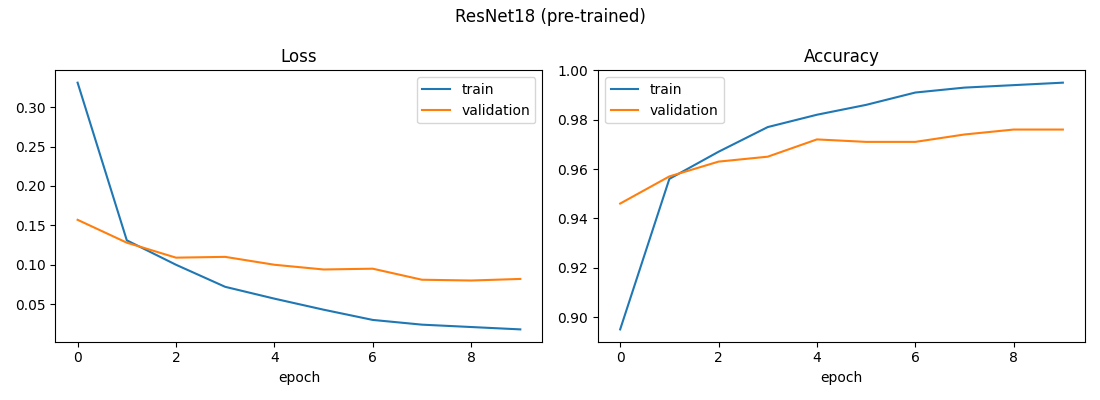

In [ ]:
plot_history(resnet_history, "ResNet18 (pre-trained)", "resnet18_curves.png")
!cp resnet18.pt resnet18_curves.png /content/drive/MyDrive/eurosat/

## 4. Evaluation on the test set

The best weights of each model are restored and both are evaluated on the held-out test set.

In [ ]:
import numpy as np

@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, labels, confs = [], [], []
    for x, y in loader:
        probs = torch.softmax(model(x.to(device)), dim=1)
        conf, pred = probs.max(1)
        preds.append(pred.cpu()); labels.append(y); confs.append(conf.cpu())
    return torch.cat(preds).numpy(), torch.cat(labels).numpy(), torch.cat(confs).numpy()

model.load_state_dict(torch.load("small_cnn.pt"))
resnet.load_state_dict(torch.load("resnet18.pt"))

cnn_pred, y_true, cnn_conf = predict(model, test_dl)
res_pred, _, res_conf = predict(resnet, test_dl)
classes = raw.classes
print("Test images:", len(y_true))

Test images: 4050


In [ ]:
import pandas as pd

def n_params(m):
    return sum(p.numel() for p in m.parameters())

results = pd.DataFrame({
    "Model": ["SmallCNN (from scratch)", "ResNet18 (pre-trained)"],
    "Parameters": [n_params(model), n_params(resnet)],
    "Epochs": [len(cnn_history), len(resnet_history)],
    "Validation": [max(h[3] for h in cnn_history), max(h[3] for h in resnet_history)],
    "Test": [(cnn_pred == y_true).mean(), (res_pred == y_true).mean()],
}).round(4)

print(results.to_markdown(index=False))

| Model                   |   Parameters |   Epochs |   Validation |   Test |
|:------------------------|-------------:|---------:|-------------:|-------:|
| SmallCNN (from scratch) |        94986 |       20 |       0.9353 | 0.9383 |
| ResNet18 (pre-trained)  |     11181642 |       10 |       0.9763 | 0.9805 |


Rows are the true class, columns the predicted class.

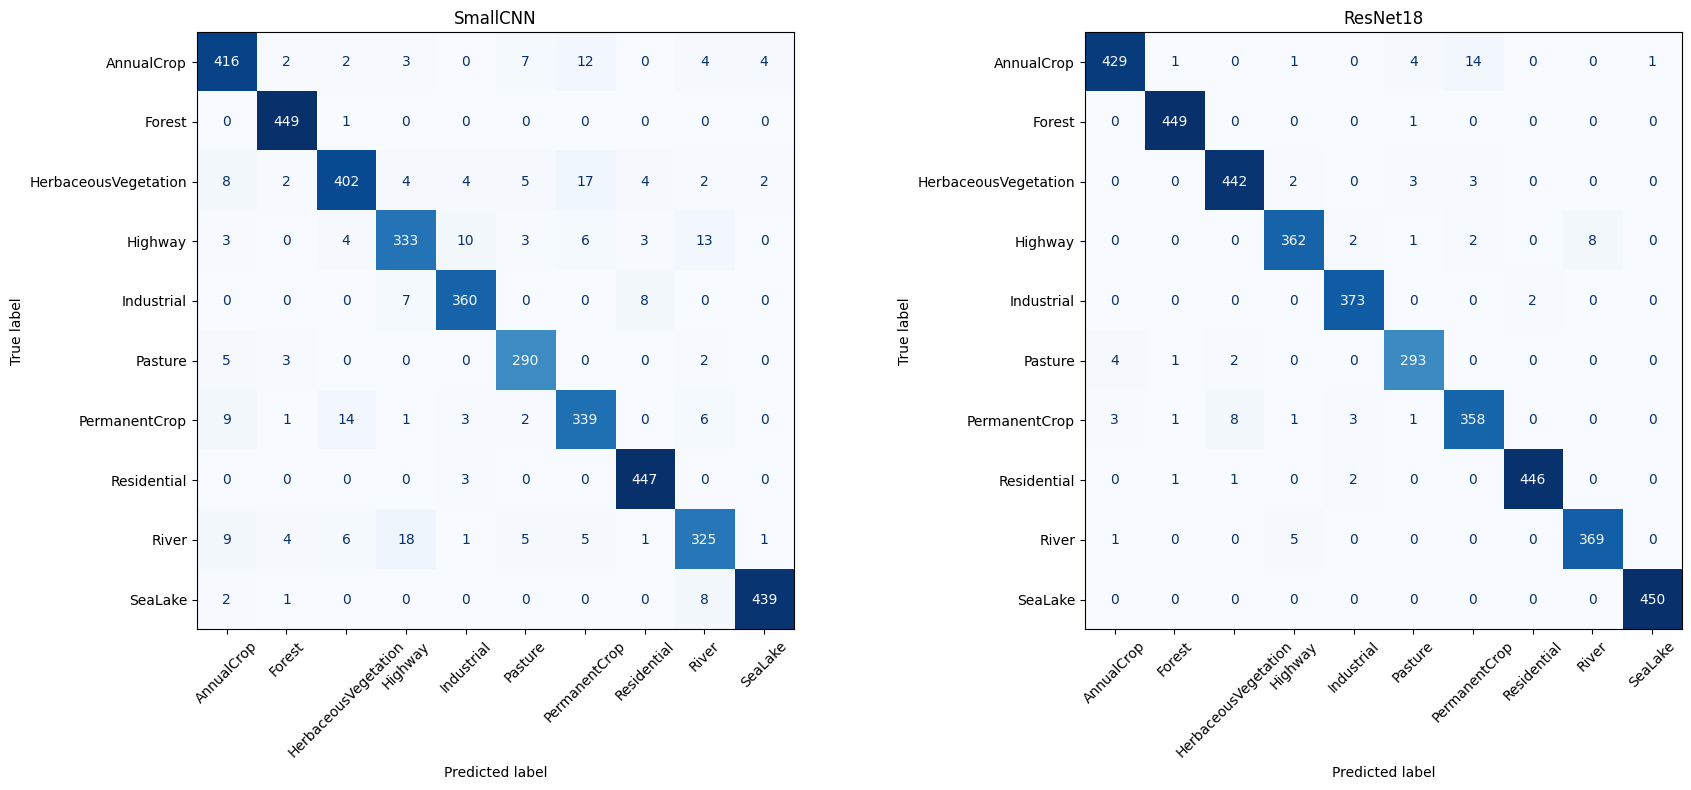

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, pred, title in [(axes[0], cnn_pred, "SmallCNN"), (axes[1], res_pred, "ResNet18")]:
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, display_labels=classes,
        xticks_rotation=45, cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

Per-class results for ResNet18 and the class pairs it confuses most often.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_true, res_pred, target_names=classes, digits=3))

cm = confusion_matrix(y_true, res_pred)
np.fill_diagonal(cm, 0)
top = np.argsort(cm, axis=None)[::-1][:5]
print("Pairs ResNet18 confuses most (true -> predicted):")
for t, p in zip(*np.unravel_index(top, cm.shape)):
    print(f"  {classes[t]} -> {classes[p]}: {cm[t, p]}")

                      precision    recall  f1-score   support

          AnnualCrop      0.982     0.953     0.967       450
              Forest      0.991     0.998     0.994       450
HerbaceousVegetation      0.976     0.982     0.979       450
             Highway      0.976     0.965     0.971       375
          Industrial      0.982     0.995     0.988       375
             Pasture      0.967     0.977     0.972       300
       PermanentCrop      0.950     0.955     0.952       375
         Residential      0.996     0.991     0.993       450
               River      0.979     0.984     0.981       375
             SeaLake      0.998     1.000     0.999       450

            accuracy                          0.980      4050
           macro avg      0.979     0.980     0.980      4050
        weighted avg      0.981     0.980     0.980      4050

Pairs ResNet18 confuses most (true -> predicted):
  AnnualCrop -> PermanentCrop: 14
  PermanentCrop -> HerbaceousVegetation: 8
  

The misclassified test images the model was most confident about. Several are arguably label noise
rather than model errors.

In [ ]:
wrong = np.where(res_pred != y_true)[0]
wrong = wrong[np.argsort(-res_conf[wrong])][:10]

mean = torch.tensor(MEAN).view(3, 1, 1)
std = torch.tensor(STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 5, figsize=(14, 6.5))
for ax, i in zip(axes.flat, wrong):
    img, _ = test_ds[int(i)]
    ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(f"true: {classes[y_true[i]]}\npredicted: {classes[res_pred[i]]} ({res_conf[i]:.2f})", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig("confident_errors.png", dpi=150)
plt.show()

In [ ]:
!cp confusion_matrices.png confident_errors.png /content/drive/MyDrive/eurosat/

## Findings

- The pre-trained ResNet18 reaches 98.1% test accuracy against 93.8% for the small CNN, cutting the
  error rate to a third, and it already beats the small CNN after its first epoch.
- Test accuracy is close to validation accuracy for both models, so model selection on the validation
  set did not overfit it.
- Most remaining errors are inside agriculture (annual crop, permanent crop, pasture) and between
  highway and river, which both appear as thin lines in a tile. Sea/lake, forest and residential are
  the most reliable classes.
- EuroSAT tiles are cut from larger scenes, so a random split places neighbouring tiles in both training
  and test sets. Accuracy on a region the model has never seen is likely lower than measured here.

## What comes next

`resnet18.pt` is the model served by the application. Downloading Sentinel-2 scenes for any place,
classifying them tile by tile and measuring change between two dates is implemented in the `backend/`
package of the repository.